<a href="https://colab.research.google.com/github/hoangvvthu/machine_learning/blob/main/_downloads/cifar10_Model2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phân loại ảnh CIFAR-10 — Model 2
Kiến trúc đầu vào: Mạng CNN nhận ảnh màu RGB có kích thước 32 × 32 pixel, gồm 3 kênh màu (Red, Green, Blue). Tensor đầu vào có dạng (C, H, W) = (3, 32, 32). Từ đầu vào này, tiến hành thiết kế các lớp Convolution, Pooling, phép cộng Tensor, phép nối Tensor và Fully Connected theo yêu cầu của từng mô hình.  
# Yêu cầu:  
Thiết kế thêm ít nhất 10 conv5x5(),  
02 maxpooling(.),   
03 torch.cat(.),  
03 cộng 2 tensors.  
Chỉ có duy nhất 02 fully connected layer (FC(.)).  
Số lượng parameters từ khoảng 10M đến 20M.


## 1. Nạp và quan sát dữ liệu CIFAR-10


In [71]:
%matplotlib inline

In [75]:
import torch
import torchvision
import torchvision.transforms as transforms

model_number = 2

In [77]:
from google.colab import drive
drive.mount('/content/drive')

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

data_path = '/content/drive/MyDrive/CIFAR10'

trainset = torchvision.datasets.CIFAR10(root=data_path, train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root=data_path, train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=4,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print("Training images:", len(trainset))
print("Testing images:", len(testset))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training images: 50000
Testing images: 10000


plane   car   cat truck


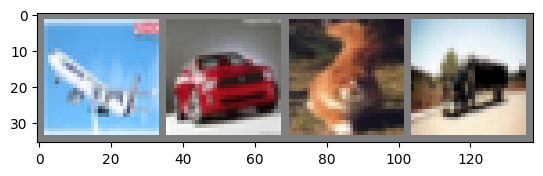

In [78]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join('%5s' % classes[labels[j]] for j in range(4)))

## 2. Khai báo mạng CNN — Model 2

10 Conv 5×5, 3 lượt MaxPool, 3 ADD, 3 CAT, 2 SPLIT và 2 FC. `__init__()` khai báo lớp; `forward()` xác định đường đi của tensor. Dùng `x` cho luồng đang xử lý, `x1`/`x2` để giữ nhánh cần dùng lại.

`[B,C,H,W]`: batch, kênh, chiều cao, chiều rộng. **ADD** cộng tensor cùng shape; **CAT** nối kênh; **SPLIT** chia kênh. Flatten trải C×H×W thành một vector cho mỗi ảnh.

| Cụm kiến trúc | Phép biến đổi | Shape đầu ra |
|---|---|---|
| Conv1 → Conv2/Conv3 | 3→6; rẽ đôi mỗi nhánh 6→12 | `[B, 12, 32, 32]` mỗi nhánh |
| MaxPool1/2 → ADD1 | 32×32→16×16; cộng hai nhánh | `[B, 12, 16, 16]` |
| Conv4/Conv5 → ADD2 | Hai nhánh 12→24, rồi ADD | `[B, 24, 16, 16]` |
| SPLIT1 → Conv6/Conv7 → ADD3 | 24→12+12; mỗi nhánh 12→24 | `[B, 24, 16, 16]` |
| Conv8 → CAT1 | 24→48; CAT(ADD2 24, Conv8 48) | `[B, 72, 16, 16]` |
| SPLIT2 → Conv9 | 72→36+36; nhánh trên 36→72 | `[B, 72, 16, 16]` |
| CAT2 / Conv10 / CAT3 | 72+36=108; 72→144; 144+108=252 | `[B, 252, 16, 16]` |
| MaxPool3 → Flatten | 252×8×8 = 16.128 | `[B, 16128]` |
| Hai lớp FC | 16128 → 1000 → 10 | `[B, 10]` |

Ba model đều dùng cùng cách khởi tạo: Kaiming cho Conv, mặc định cho FC. FC cuối tạo 10 logits, không qua ReLU hoặc Softmax trước `CrossEntropyLoss`.


In [79]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv khai báo số kênh vào/ra, kernel, stride, padding; forward xác định đường nối.
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5, stride=1, padding=2)
        self.conv2 = nn.Conv2d(6, 12, kernel_size=5, stride=1, padding=2)
        self.conv3 = nn.Conv2d(6, 12, kernel_size=5, stride=1, padding=2)
        self.conv4 = nn.Conv2d(12, 24, kernel_size=5, stride=1, padding=2)
        self.conv5 = nn.Conv2d(12, 24, kernel_size=5, stride=1, padding=2)
        self.conv6 = nn.Conv2d(12, 24, kernel_size=5, stride=1, padding=2)
        self.conv7 = nn.Conv2d(12, 24, kernel_size=5, stride=1, padding=2)
        self.conv8 = nn.Conv2d(24, 48, kernel_size=5, stride=1, padding=2)
        self.conv9 = nn.Conv2d(36, 72, kernel_size=5, stride=1, padding=2)
        self.conv10 = nn.Conv2d(72, 144, kernel_size=5, stride=1, padding=2)
        # Cùng module MaxPool có thể được gọi ở nhiều vị trí trong forward.
        self.pool = nn.MaxPool2d(2, 2)
        # FC1 nhận vector Flatten; lớp FC cuối tạo 10 logits.
        self.fc1 = nn.Linear(252 * 8 * 8, 1000)
        self.fc2 = nn.Linear(1000, 10)

        # ReLU: khởi tạo Conv bằng Kaiming để tín hiệu qua mạng sâu ổn định hơn.
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        # KHỐI 1: Ảnh RGB -> Conv1: [B,3,32,32] -> [B,6,32,32].
        x = F.relu(self.conv1(x))

        # KHỐI 2: Hai nhánh Conv rồi Pool; giữ MaxPool2 trong x cho Conv5.
        x1 = self.pool(F.relu(self.conv2(x)))  # MaxPool1: [B,12,16,16].
        x = self.pool(F.relu(self.conv3(x)))   # MaxPool2: [B,12,16,16].
        x1 = x1 + x                           # ADD1: [B,12,16,16].
        x1 = F.relu(self.conv4(x1))            # Conv4 lấy ADD1: 12 -> 24.
        x = F.relu(self.conv5(x))              # Conv5 lấy MaxPool2: 12 -> 24.
        x = x1 + x                            # ADD2: [B,24,16,16].

        # KHỐI 3: Giữ ADD2 trong x cho CAT1; cần x1 và x2 cho hai nửa SPLIT1.
        x1, x2 = torch.chunk(x, 2, dim=1)      # Chia 24 kênh thành 12+12.
        x1 = F.relu(self.conv6(x1))            # Nhóm đầu: 12 -> 24.
        x2 = F.relu(self.conv7(x2))            # Nhóm sau: 12 -> 24.
        x1 = x1 + x2                          # ADD3: [B,24,16,16].
        x1 = F.relu(self.conv8(x1))            # Conv8: 24 -> 48.
        x = torch.cat((x, x1), dim=1)          # CAT1 = ADD2 24 + Conv8 48 = 72.

        # KHỐI 4: Không cần giữ CAT1 nữa; dùng lại x cho nhánh Conv9 -> Conv10.
        x, x1 = torch.chunk(x, 2, dim=1)       # SPLIT2: 36+36 kênh.
        x = F.relu(self.conv9(x))              # Conv9: nhóm đầu 36 -> 72.
        x1 = torch.cat((x, x1), dim=1)         # CAT2 = Conv9 72 + nhóm sau 36 = 108.
        x = F.relu(self.conv10(x))             # Conv10 lấy Conv9: 72 -> 144.
        x = torch.cat((x, x1), dim=1)          # CAT3 = Conv10 144 + CAT2 108 = 252.

        # KHỐI 5: MaxPool3 -> Flatten -> đúng hai lớp FC.
        x = self.pool(x)                      # [B,252,8,8].
        x = torch.flatten(x, 1)               # 252*8*8 = 16128 đặc trưng/ảnh.
        x = F.relu(self.fc1(x))               # 16128 -> 1000.
        x = self.fc2(x)                       # [B,10]: 10 logits.
        return x

net = Net()
from torchsummary import summary
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = net.to(device)
summary(net, (3, 32, 32), device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 32, 32]             456
            Conv2d-2           [-1, 12, 32, 32]           1,812
         MaxPool2d-3           [-1, 12, 16, 16]               0
            Conv2d-4           [-1, 12, 32, 32]           1,812
         MaxPool2d-5           [-1, 12, 16, 16]               0
            Conv2d-6           [-1, 24, 16, 16]           7,224
            Conv2d-7           [-1, 24, 16, 16]           7,224
            Conv2d-8           [-1, 24, 16, 16]           7,224
            Conv2d-9           [-1, 24, 16, 16]           7,224
           Conv2d-10           [-1, 48, 16, 16]          28,848
           Conv2d-11           [-1, 72, 16, 16]          64,872
           Conv2d-12          [-1, 144, 16, 16]         259,344
        MaxPool2d-13            [-1, 252, 8, 8]               0
           Linear-14                 [-

## 3. Hàm mất mát và bộ tối ưu

`CrossEntropyLoss` so sánh logits với nhãn thật. Cả ba model dùng SGD với `lr=0.001`, `momentum=0.9`, `weight_decay=0`.


In [81]:
learning_rate = 0.001
momentum = 0.9
weight_decay = 0.0

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    net.parameters(), lr=learning_rate, momentum=momentum, weight_decay=weight_decay
)

print("Loss function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)
print("Momentum:", momentum)
print("Weight decay:", weight_decay)

Loss function: CrossEntropyLoss
Optimizer: SGD
Learning rate: 0.001
Momentum: 0.9
Weight decay: 0.0


## 4. Huấn luyện mạng

Mỗi batch: **xóa gradient → forward → tính loss → backward → cập nhật weights**. Chạy 10 epochs. Loss/accuracy dưới đây được tính trên train trong lúc model học.


In [82]:
num_epochs = 10
train_loss_history = []
train_accuracy_history = []

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in trainloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = net(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = 100.0 * correct_predictions / total_samples
    train_loss_history.append(epoch_loss)
    train_accuracy_history.append(epoch_accuracy)
    print(f"Epoch [{epoch + 1}/{num_epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_accuracy:.2f}%")

print("Finished Training")

Epoch [1/10] - Loss: 1.4375 - Accuracy: 47.79%
Epoch [2/10] - Loss: 0.9826 - Accuracy: 65.49%
Epoch [3/10] - Loss: 0.7643 - Accuracy: 73.19%
Epoch [4/10] - Loss: 0.5835 - Accuracy: 79.39%
Epoch [5/10] - Loss: 0.4350 - Accuracy: 84.82%
Epoch [6/10] - Loss: 0.3286 - Accuracy: 88.62%
Epoch [7/10] - Loss: 0.2758 - Accuracy: 90.63%
Epoch [8/10] - Loss: 0.2493 - Accuracy: 91.69%
Epoch [9/10] - Loss: 0.2225 - Accuracy: 92.88%
Epoch [10/10] - Loss: 0.2084 - Accuracy: 93.27%
Finished Training


### Biểu đồ huấn luyện

Theo dõi loss và accuracy theo epoch; kết quả test được tính riêng ở phần 5.


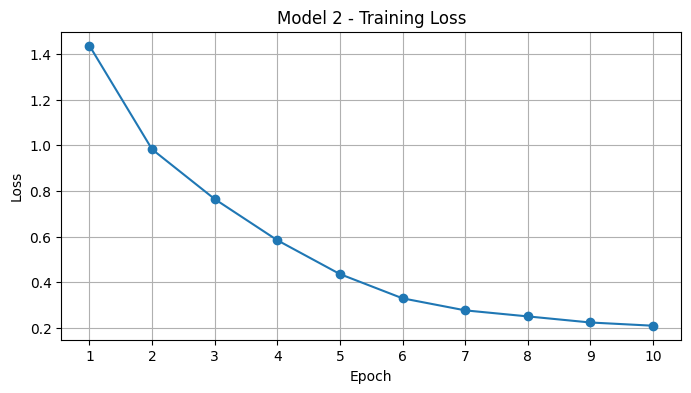

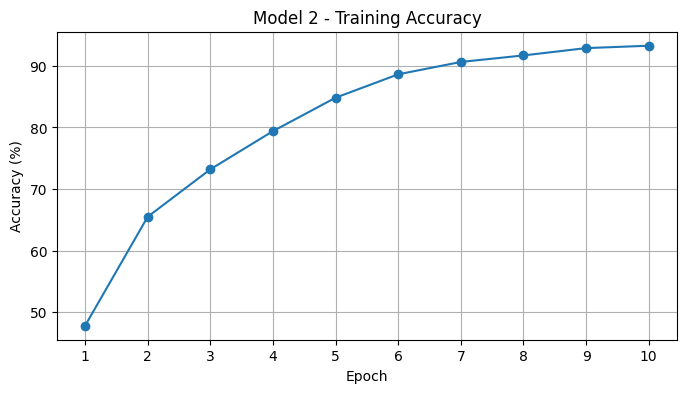

In [83]:
epochs = range(1, len(train_loss_history) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_loss_history, marker="o")
plt.title(f"Model {model_number} - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_accuracy_history, marker="o")
plt.title(f"Model {model_number} - Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.grid(True)
plt.show()

## 5. Kiểm tra trên dữ liệu test

Xem nhãn thật và dự đoán của một batch. Mỗi ảnh có 10 logits; `argmax(dim=1)` chọn lớp có điểm lớn nhất.


Ground truth: cat ship ship plane
Predicted:    cat ship ship plane


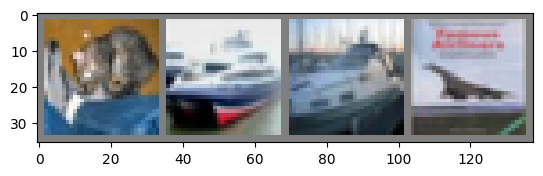

In [84]:
test_images, test_labels = next(iter(testloader))
imshow(torchvision.utils.make_grid(test_images))

net.eval()
with torch.no_grad():
    test_outputs = net(test_images.to(device))
predicted_classes = test_outputs.argmax(dim=1).cpu()

print("Ground truth:", " ".join(classes[label.item()] for label in test_labels))
print("Predicted:   ", " ".join(classes[label.item()] for label in predicted_classes))

### 5.1. Đánh giá toàn bộ 10.000 ảnh test

`eval()` đặt chế độ đánh giá; `no_grad()` tắt tính gradient. Phần này không cập nhật weights.


In [85]:
net.eval()
running_test_loss = 0.0
correct_test_predictions = 0
total_test_samples = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = net(images)
        loss = criterion(outputs, labels)
        running_test_loss += loss.item() * labels.size(0)
        correct_test_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_test_samples += labels.size(0)

test_loss = running_test_loss / total_test_samples
test_accuracy = 100.0 * correct_test_predictions / total_test_samples
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 1.5226
Test Accuracy: 70.60%


### 5.2. Kết quả từng lớp

Mỗi lớp test có 1.000 ảnh. Tỷ lệ dưới đây là số nhận đúng chia cho số ảnh có nhãn thật thuộc lớp đó.


In [86]:
class_correct = [0] * len(classes)
class_total = [0] * len(classes)

net.eval()
with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        predictions = net(images).argmax(dim=1)
        for label, prediction in zip(labels.cpu(), predictions.cpu()):
            index = label.item()
            class_total[index] += 1
            class_correct[index] += int(prediction.item() == index)

class_accuracy = []
for index, name in enumerate(classes):
    accuracy = 100.0 * class_correct[index] / class_total[index]
    class_accuracy.append(accuracy)
    print(f"{name:>10}: {accuracy:6.2f}% ({class_correct[index]}/{class_total[index]})")

     plane:  70.80% (708/1000)
       car:  87.90% (879/1000)
      bird:  58.80% (588/1000)
       cat:  51.20% (512/1000)
      deer:  69.40% (694/1000)
       dog:  63.40% (634/1000)
      frog:  76.40% (764/1000)
     horse:  72.30% (723/1000)
      ship:  81.60% (816/1000)
     truck:  74.20% (742/1000)


### 5.3. Tổng kết

Số liệu được lấy từ các biến vừa tính. Train Accuracy cao chưa bảo đảm Test Accuracy cao; kết quả có thể thay đổi giữa các lần chạy.


In [87]:
total_params = sum(parameter.numel() for parameter in net.parameters())
best_class = max(range(len(classes)), key=lambda index: class_accuracy[index])
worst_class = min(range(len(classes)), key=lambda index: class_accuracy[index])

print(f"===== Model {model_number} Summary =====")
print(f"Total parameters: {total_params:,}")
print(f"Completed epochs: {len(train_loss_history)}")
print(f"Final training loss: {train_loss_history[-1]:.4f}")
print(f"Final training accuracy: {train_accuracy_history[-1]:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Train-test accuracy gap: {train_accuracy_history[-1] - test_accuracy:.2f} percentage points")
print(f"Best class: {classes[best_class]} ({class_accuracy[best_class]:.2f}%)")
print(f"Lowest class: {classes[worst_class]} ({class_accuracy[worst_class]:.2f}%)")


===== Model 2 Summary =====
Total parameters: 16,525,050
Completed epochs: 10
Final training loss: 0.2084
Final training accuracy: 93.27%
Test loss: 1.5226
Test accuracy: 70.60%
Train-test accuracy gap: 22.67 percentage points
Best class: car (87.90%)
Lowest class: cat (51.20%)
